# SteamSpy Tag Data: Audit and Decay-Curve Comparison

This notebook audits the source dataset, verifies the empirical target vectors, and compares four constrained positional decay functions using shared and separate parameters by tag-list length. Existing empirical CSVs are verified and preserved; fitting outputs are written under `results/`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Resolve the dataset whether Jupyter starts in the project root or this study folder.
candidates = [
    Path('Tag Weights DB/steamspy_tag_data.csv'),
    Path('Tag Weight Study/Tag Weights DB/steamspy_tag_data.csv'),
    Path('../Tag Weights DB/steamspy_tag_data.csv'),
    Path('../Tag Weight Study/Tag Weights DB/steamspy_tag_data.csv'),
]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Could not find steamspy_tag_data.csv. Checked: ' + ', '.join(map(str, candidates)))

print(f'Working directory: {Path.cwd()}')
print(f'Dataset file: {data_path.resolve()}')
df = pd.read_csv(data_path, encoding='utf-8-sig')
print(f'Rows: {len(df):,} | Columns: {len(df.columns):,}')
display(df.head())

def save_or_verify_csv(frame, path):
    """Preserve existing empirical inputs; write only if the output is absent."""
    if path.exists():
        saved = pd.read_csv(path)
        pd.testing.assert_frame_equal(frame, saved, check_dtype=False,
                                      check_exact=False, rtol=0, atol=1e-12)
        print(f'Verified existing CSV without overwriting: {path.name}')
    else:
        frame.to_csv(path, index=False, encoding='utf-8')
        print(f'Created CSV: {path.name}')


Working directory: /Users/abhinav/Work/Bits 1st sem/Data Mining/SteamDataset Preprocessing/Tag Weight Study
Dataset file: /Users/abhinav/Work/Bits 1st sem/Data Mining/SteamDataset Preprocessing/Tag Weight Study/Tag Weights DB/steamspy_tag_data.csv
Rows: 29,022 | Columns: 372


,appid,1980s,1990s,2.5d,2d,2d_fighter,360_video,3d,3d_platformer,3d_vision,...,warhammer_40k,web_publishing,werewolves,western,word_game,world_war_i,world_war_ii,wrestling,zombies,e_sports
0,10,144,564,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,550
1,20,0,71,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,30,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,5,122,0,0,0
3,40,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,50,0,77,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Structure and column checks

The file is expected to have one `appid` column and one column per tag. Tag cells are vote counts; zero means no recorded votes for that game/tag pair.

In [2]:
print('Column names:')
display(pd.Series(df.columns, name='column'))
print('Data types:')
display(df.dtypes.value_counts().rename_axis('dtype').to_frame('column_count'))
duplicate_column_names = df.columns[df.columns.duplicated()].tolist()
print('Duplicate column names:', duplicate_column_names)
print('AppID column present:', 'appid' in df.columns)

Column names:


0             appid
1             1980s
2             1990s
3              2.5d
4                2d
           ...     
367     world_war_i
368    world_war_ii
369       wrestling
370         zombies
371        e_sports
Name: column, Length: 372, dtype: str

Data types:


,column_count
dtype,
int64,372


Duplicate column names: []
AppID column present: True


## Missing values and duplicate records

In [3]:
missing_by_column = df.isna().sum().sort_values(ascending=False)
print(f'Total missing cells: {int(missing_by_column.sum()):,}')
display(missing_by_column[missing_by_column.gt(0)].rename('missing_cells').to_frame())
print(f'Completely duplicated rows: {int(df.duplicated().sum()):,}')

if 'appid' in df.columns:
    print(f'Missing AppIDs: {int(df["appid"].isna().sum()):,}')
    print(f'Duplicate AppID rows after first occurrence: {int(df["appid"].duplicated().sum()):,}')
    print(f'Unique AppIDs: {df["appid"].nunique(dropna=True):,}')
    print('Sample duplicate AppIDs:', df.loc[df['appid'].duplicated(keep=False), 'appid'].head(20).tolist())

Total missing cells: 0


,missing_cells


Completely duplicated rows: 0
Missing AppIDs: 0
Duplicate AppID rows after first occurrence: 0
Unique AppIDs: 29,022
Sample duplicate AppIDs: []


## Tag-count and numeric-value checks

These checks distinguish missing values from legitimate zeros, summarize how many tags each game has, and flag unexpected negative or non-integer vote counts.

In [4]:
tag_columns = [c for c in df.columns if c != 'appid']
tag_values = df[tag_columns].apply(pd.to_numeric, errors='coerce')
non_numeric_cells = int(tag_values.isna().sum().sum()) - int(df[tag_columns].isna().sum().sum())
negative_cells = int((tag_values < 0).sum().sum())
fractional_cells = int(((tag_values % 1) != 0).where(tag_values.notna(), False).sum().sum())
games_with_no_nonzero_tags = int(tag_values.fillna(0).ne(0).sum(axis=1).eq(0).sum())
tags_per_game = tag_values.fillna(0).ne(0).sum(axis=1)

print(f'Tag columns: {len(tag_columns):,}')
print(f'Non-numeric tag cells: {non_numeric_cells:,}')
print(f'Negative tag counts: {negative_cells:,}')
print(f'Non-integer tag counts: {fractional_cells:,}')
print(f'Games with zero nonzero tag counts: {games_with_no_nonzero_tags:,}')
print('Tags per game summary:')
display(tags_per_game.describe().to_frame('number_of_nonzero_tags'))
print('Games by number of nonzero tags:')
display(tags_per_game.value_counts().sort_index().rename_axis('nonzero_tag_count').to_frame('games'))
print('Most commonly populated tag columns:')
display(tag_values.gt(0).sum().sort_values(ascending=False).head(20).rename('games_with_votes').to_frame())

Tag columns: 371
Non-numeric tag cells: 0
Negative tag counts: 0
Non-integer tag counts: 0
Games with zero nonzero tag counts: 575
Tags per game summary:


,number_of_nonzero_tags
count,29022.000000
mean,7.429984
std,5.568297
min,0.000000
25%,3.000000
50%,5.000000
75%,10.000000
max,21.000000


Games by number of nonzero tags:


,games
nonzero_tag_count,
0,575
1,759
2,2312
3,4100
4,3893
5,3037
6,2386
7,1791
8,1391


Most commonly populated tag columns:


,games_with_votes
indie,20782
action,13136
adventure,11572
casual,11449
singleplayer,6779
strategy,6000
simulation,5855
rpg,4900
early_access,3822
puzzle,3298


## Convert the wide tag matrix to indexed tag-count records

Create one output row per AppID with `n_tags` and a JSON object mapping each nonzero tag to its SteamSpy vote count. Zero entries are omitted because they mean no recorded votes. Games with no nonzero tags are retained with an empty object. This keeps the full observed range of `n_tags`, including 21, for stratified decay experiments.

In [5]:
import json

indexed_rows = []
for appid, values in zip(df['appid'], tag_values.itertuples(index=False, name=None)):
    # Sort by vote count descending; Python's stable sort preserves source order for ties.
    sorted_pairs = sorted(
        ((tag, int(value)) for tag, value in zip(tag_columns, values)
         if pd.notna(value) and value > 0),
        key=lambda pair: pair[1],
        reverse=True,
    )
    tag_count_pairs = dict(sorted_pairs)
    indexed_rows.append({
        'appid': int(appid),
        'n_tags': len(tag_count_pairs),
        'tag_counts': json.dumps(tag_count_pairs, ensure_ascii=False, separators=(',', ':'))
    })

indexed_df = pd.DataFrame(indexed_rows, columns=['appid', 'n_tags', 'tag_counts'])
# Write beside the source dataset, inside Tag Weight Study.
output_path = data_path.parent.parent / 'steamspy_tag_data_indexed.csv'
save_or_verify_csv(indexed_df, output_path)
print(f'Indexed output: {len(indexed_df):,} games at {output_path.resolve()}')
print('Games by n_tags:')
display(indexed_df['n_tags'].value_counts().sort_index().rename_axis('n_tags').to_frame('games'))
display(indexed_df.head())

Verified existing CSV without overwriting: steamspy_tag_data_indexed.csv
Indexed output: 29,022 games at /Users/abhinav/Work/Bits 1st sem/Data Mining/SteamDataset Preprocessing/Tag Weight Study/steamspy_tag_data_indexed.csv
Games by n_tags:


,games
n_tags,
0,575
1,759
2,2312
3,4100
4,3893
5,3037
6,2386
7,1791
8,1391


,appid,n_tags,tag_counts
0,10,20,"{""action"":2681,""fps"":2048,""multiplayer"":1659,""..."
1,20,20,"{""action"":208,""fps"":188,""multiplayer"":172,""cla..."
2,30,16,"{""fps"":138,""world_war_ii"":122,""multiplayer"":11..."
3,40,8,"{""action"":85,""fps"":71,""multiplayer"":58,""classi..."
4,50,20,"{""fps"":235,""action"":211,""sci_fi"":166,""singlepl..."


## Average max-scaled decay vectors by `n_tags`

For each game with at least one tag, divide every ranked tag count by that game’s largest count (the rank-1 count). Then, for each `n_tags` group, average the normalized counts rank by rank. The output is wide-form: one row per `n_tags`, with `weight_rank_1`, `weight_rank_2`, and so on. `n_games` records how many games contributed. The `n_tags = 0` group is retained with blank weight columns because it has no tag vector.

In [6]:
from collections import defaultdict

normalized_vectors_by_n = defaultdict(list)
for row in indexed_df.itertuples(index=False):
    counts = list(json.loads(row.tag_counts).values())
    if counts:  # n_tags == 0 has no vector to normalize or average
        max_count = counts[0]  # tag_counts is already sorted in descending order
        normalized_vectors_by_n[row.n_tags].append([count / max_count for count in counts])

max_n_tags = int(indexed_df['n_tags'].max())
average_rows = []
for n_tags, game_vectors in sorted(
    ((int(n), vectors) for n, vectors in indexed_df.groupby('n_tags').groups.items()),
    key=lambda item: item[0],
):
    vectors = normalized_vectors_by_n.get(n_tags, [])
    result = {'n_tags': n_tags, 'n_games': len(indexed_df[indexed_df['n_tags'] == n_tags])}
    for rank in range(1, max_n_tags + 1):
        result[f'weight_rank_{rank}'] = (
            sum(vector[rank - 1] for vector in vectors) / len(vectors)
            if vectors and rank <= n_tags else None
        )
    average_rows.append(result)

average_decay_df = pd.DataFrame(average_rows)
average_decay_path = data_path.parent.parent / 'steamspy_average_decay_by_n_tags.csv'
save_or_verify_csv(average_decay_df, average_decay_path)
print(f'Empirical target file: {average_decay_path.resolve()}')
display(average_decay_df)

Verified existing CSV without overwriting: steamspy_average_decay_by_n_tags.csv
Empirical target file: /Users/abhinav/Work/Bits 1st sem/Data Mining/SteamDataset Preprocessing/Tag Weight Study/steamspy_average_decay_by_n_tags.csv


,n_tags,n_games,weight_rank_1,weight_rank_2,weight_rank_3,weight_rank_4,weight_rank_5,weight_rank_6,weight_rank_7,weight_rank_8,...,weight_rank_12,weight_rank_13,weight_rank_14,weight_rank_15,weight_rank_16,weight_rank_17,weight_rank_18,weight_rank_19,weight_rank_20,weight_rank_21
0,0,575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,759,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2312,1.0,0.756788,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,4100,1.0,0.897155,0.635319,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,3893,1.0,0.913232,0.778841,0.513915,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5,3037,1.0,0.905119,0.788681,0.636049,0.431089,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6,2386,1.0,0.895139,0.780113,0.655259,0.533643,0.379011,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7,1791,1.0,0.885193,0.756527,0.636084,0.538557,0.443217,0.331711,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8,1391,1.0,0.879850,0.755522,0.640422,0.553104,0.470650,0.389437,0.296533,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9,1097,1.0,0.874791,0.745607,0.634262,0.548041,0.468936,0.406765,0.345174,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Audit summary

The source and saved empirical CSVs must agree before curve fitting. Existing CSVs are not overwritten: if a source change makes them stale, the notebook stops with a comparison error. To regenerate deliberately, archive those two outputs first and rerun. Missing rank cells beyond a group's list length remain absent, never zero-filled.

# Four decay families

Use normalized position $x=(r-1)/(k-1)$ for $k>1$. All candidates have one fitted parameter, start at weight 1, remain in $[0,1]$, and are non-increasing.

| Family | Function | Constraint |
|---|---|---|
| Linear | $1-a x$ | $0\le a\le1$ |
| Exponential | $e^{-\lambda x}$ | $\lambda\ge0$ |
| Logarithmic | $1-a\ln(1+x)/\ln 2$ | $0\le a\le1$ |
| Power | $(1+x)^{-p}$ | $p\ge0$ |

Fit each family once across all lengths, then separately for each length. The straight line is anchored at $(0,1)$, matching the empirical normalization; it is not unconstrained ordinary least squares.

In [7]:
import sys
import numpy as np
from IPython.display import Image, Markdown

study_dir = data_path.parent.parent.resolve()
if str(study_dir) not in sys.path:
    sys.path.insert(0, str(study_dir))
import fit_decay as decay

study_result = decay.run_study(study_dir)
results_dir = study_result['output_dir']
selected_model = study_result['selected_model']
print('Verified source rows:', study_result['audit']['source_rows'])
print('Maximum recomputed mean difference:', study_result['audit']['maximum_empirical_mean_difference'])
print('Results folder:', results_dir)


Matplotlib is building the font cache; this may take a moment.


Verified source rows: 29022
Maximum recomputed mean difference: 0.0
Results folder: /Users/abhinav/Work/Bits 1st sem/Data Mining/SteamDataset Preprocessing/Tag Weight Study/results


## Scoring and selection

For $k=2,\ldots,21$, compute $\mathrm{MSE}_k=\frac{1}{k-1}\sum_{r=2}^{k}(\hat w_{k,r}-\mu_{k,r})^2$. Shared parameters minimize $\frac{1}{20}\sum_k\mathrm{MSE}_k$; **group-balanced RMSE** is the square root of that quantity. Rank 1, zero-tag groups, singleton groups, and missing cells outside a vector contribute no error.

The sensitivity metric is $\sum_k N_k\mathrm{MSE}_k/\sum_k N_k$, evaluated with the same fitted parameters. Its square root is sample-weighted RMSE. Neither reported overall RMSE is the arithmetic mean of per-group RMSEs. The recommended shared rule is the one with the lowest full-data group-balanced MSE.

In [8]:
scores = pd.DataFrame(study_result['scores'])
parameters = pd.DataFrame(study_result['parameters'])
errors = pd.DataFrame(study_result['errors'])
predictions = pd.DataFrame(study_result['predictions'])
shared_scores = scores.query("scenario == 'all_groups' and fit_type == 'shared'").sort_values('rank')
shared_parameters = parameters.query("scenario == 'all_groups' and fit_type == 'shared'")
display(shared_scores.merge(shared_parameters[['family', 'parameter_name', 'parameter']], on='family')
        [['rank', 'family', 'parameter_name', 'parameter', 'group_balanced_mse',
          'group_balanced_rmse', 'sample_weighted_mse', 'sample_weighted_rmse']])

# Check saved CLI-compatible tables against the exact objects used here.
for table, filename in [(scores, 'model_scores.csv'), (parameters, 'fitted_parameters.csv'),
                        (errors, 'per_group_errors.csv'), (predictions, 'predictions.csv')]:
    pd.testing.assert_frame_equal(table.replace('', np.nan), pd.read_csv(results_dir / filename),
                                  check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
print('All exported numerical tables match notebook results.')


,rank,family,parameter_name,parameter,group_balanced_mse,group_balanced_rmse,sample_weighted_mse,sample_weighted_rmse
0,1,power,p,1.458501,0.027495,0.165817,0.045295,0.212826
1,2,exponential,lambda,1.107038,0.029572,0.171965,0.047303,0.217492
2,3,logarithmic,a,0.678220,0.031728,0.178124,0.046409,0.215428
3,4,linear,a,0.709861,0.037506,0.193664,0.049471,0.222421


All exported numerical tables match notebook results.


In [9]:
linear_parameter = float(shared_parameters.loc[shared_parameters.family.eq('linear'), 'parameter'].iloc[0])
display(Markdown(f"**Selected shared family:** {selected_model['family']}, "
                 f"`{selected_model['equation']}`, `{selected_model['parameter_name']}={selected_model['parameter']:.10g}`. "
                 f"**Best straight line:** `w = 1 - {linear_parameter:.10g} x`."))
display(pd.DataFrame(json.loads((results_dir / 'selected_model.json').read_text())['scores'], index=[0]))


**Selected shared family:** power, `w(r,k) = (1+x)^(-p)`, `p=1.458500902`. **Best straight line:** `w = 1 - 0.7098613871 x`.

,scenario,fit_type,family,n_groups,n_games,n_parameters,group_balanced_mse,group_balanced_rmse,sample_weighted_mse,sample_weighted_rmse,rank
0,all_groups,shared,power,20,27688,1,0.027495,0.165817,0.045295,0.212826,1


## Shared rule versus separate fits

Separate fitting assigns one parameter to each of the 20 informative tag-list lengths. These fits are a descriptive accuracy benchmark with 20 parameters per family. The shared rule uses one parameter. Lower in-sample error for separate fits is not a generalization or recommendation-quality result.

In [10]:
full_scores = scores.query("scenario == 'all_groups'")
comparison = full_scores.pivot(index='family', columns='fit_type', values='group_balanced_rmse')
comparison['mse_reduction_percent'] = 100 * (1 - (comparison.per_length / comparison.shared) ** 2)
display(comparison.sort_values('shared'))
per_length_winner = full_scores.query("fit_type == 'per_length'").sort_values('rank').iloc[0]['family']
print('Best per-length family:', per_length_winner)


fit_type,per_length,shared,mse_reduction_percent
family,,,
power,0.043965,0.165817,92.970133
exponential,0.040460,0.171965,94.464215
logarithmic,0.064976,0.178124,86.693800
linear,0.088749,0.193664,78.999691


Best per-length family: exponential


## Sensitivity: remove the 12-game, 21-tag group

Refit the shared parameters after excluding `k=21`; also summarize separate fits on the remaining lengths. This checks whether the sparse group changes the family selection. The full-data winner remains the saved shared model.

,rank,family,group_balanced_mse,group_balanced_rmse,sample_weighted_mse,sample_weighted_rmse
11,1,power,0.027549,0.165978,0.043502,0.208571
9,2,exponential,0.029566,0.171947,0.045360,0.212980
10,3,logarithmic,0.031515,0.177525,0.044574,0.211126
8,4,linear,0.037072,0.192541,0.047539,0.218034


Shared winner changed: False


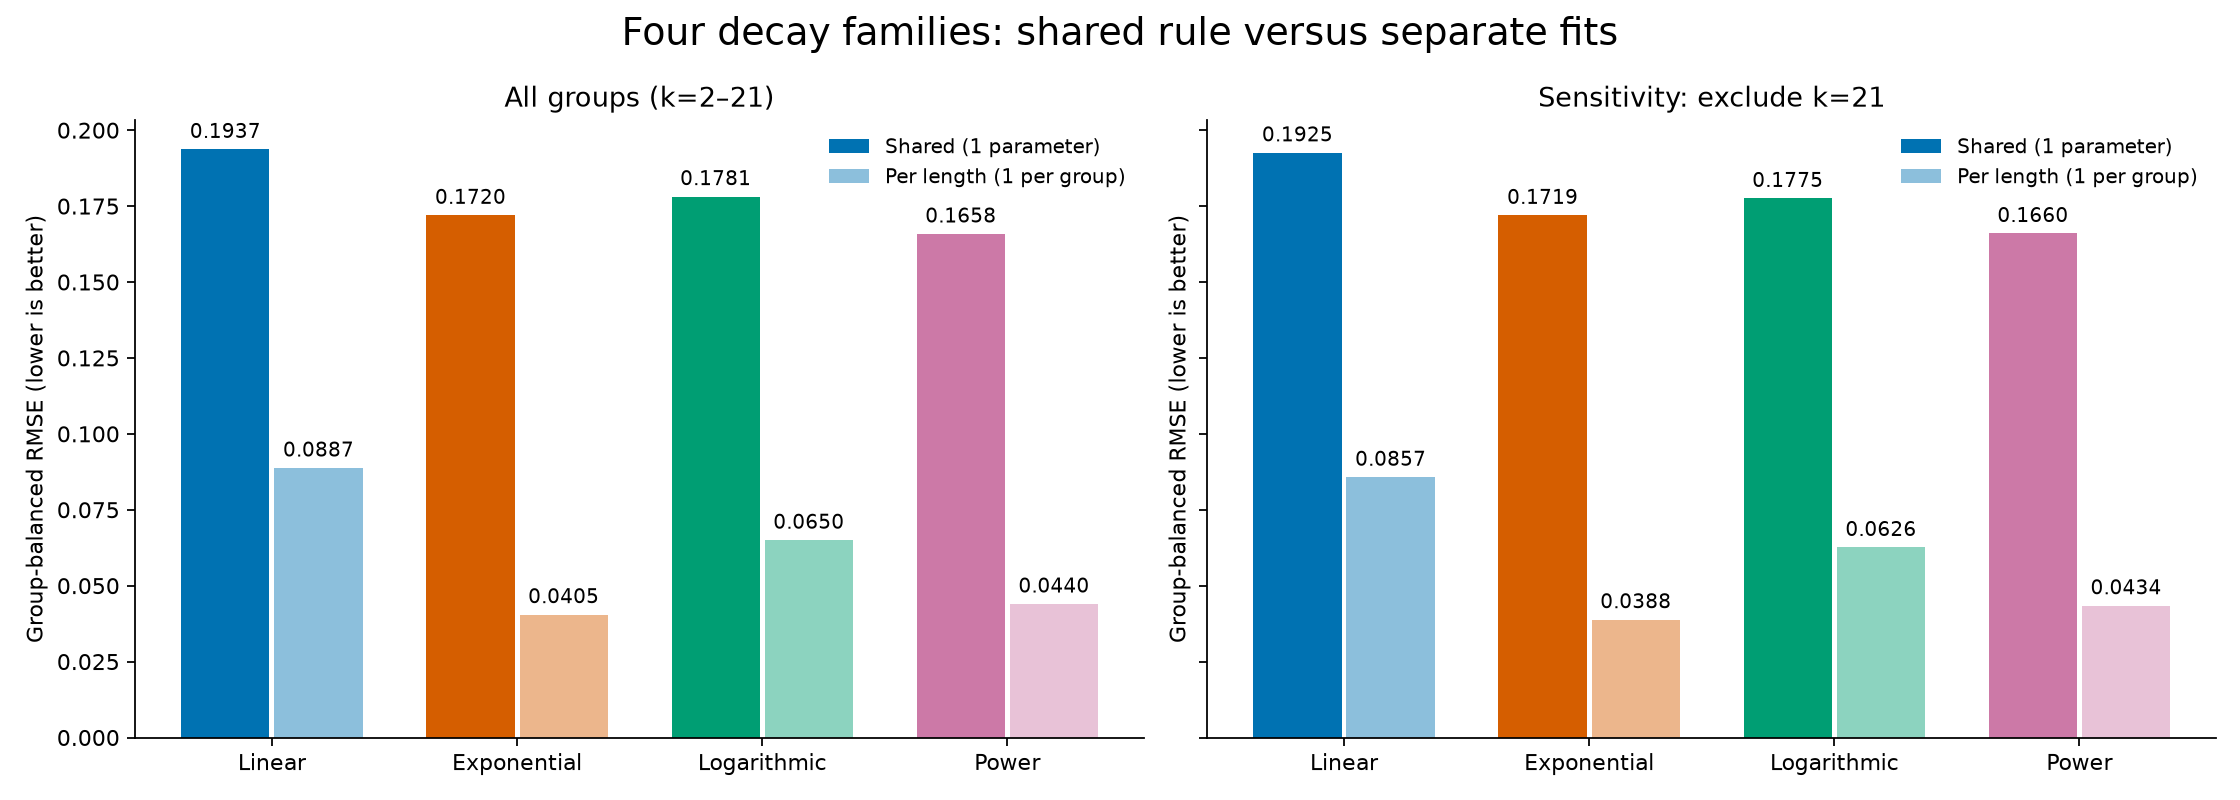

In [11]:
sensitivity = scores.query("scenario == 'without_k21' and fit_type == 'shared'").sort_values('rank')
display(sensitivity[['rank', 'family', 'group_balanced_mse', 'group_balanced_rmse',
                     'sample_weighted_mse', 'sample_weighted_rmse']])
print('Shared winner changed:', sensitivity.iloc[0]['family'] != selected_model['family'])
display(Image(filename=str(results_dir / 'model_comparison.png'), width=1200))


## Empirical points and fitted curves for every length

The dark dots are empirical means, including rank 1 for reference. Curves are shown at continuous normalized positions; scores use only the observed ranks after rank 1. Each panel lists its sample size. The sparse 21-tag group retains its unusually low last-rank target.

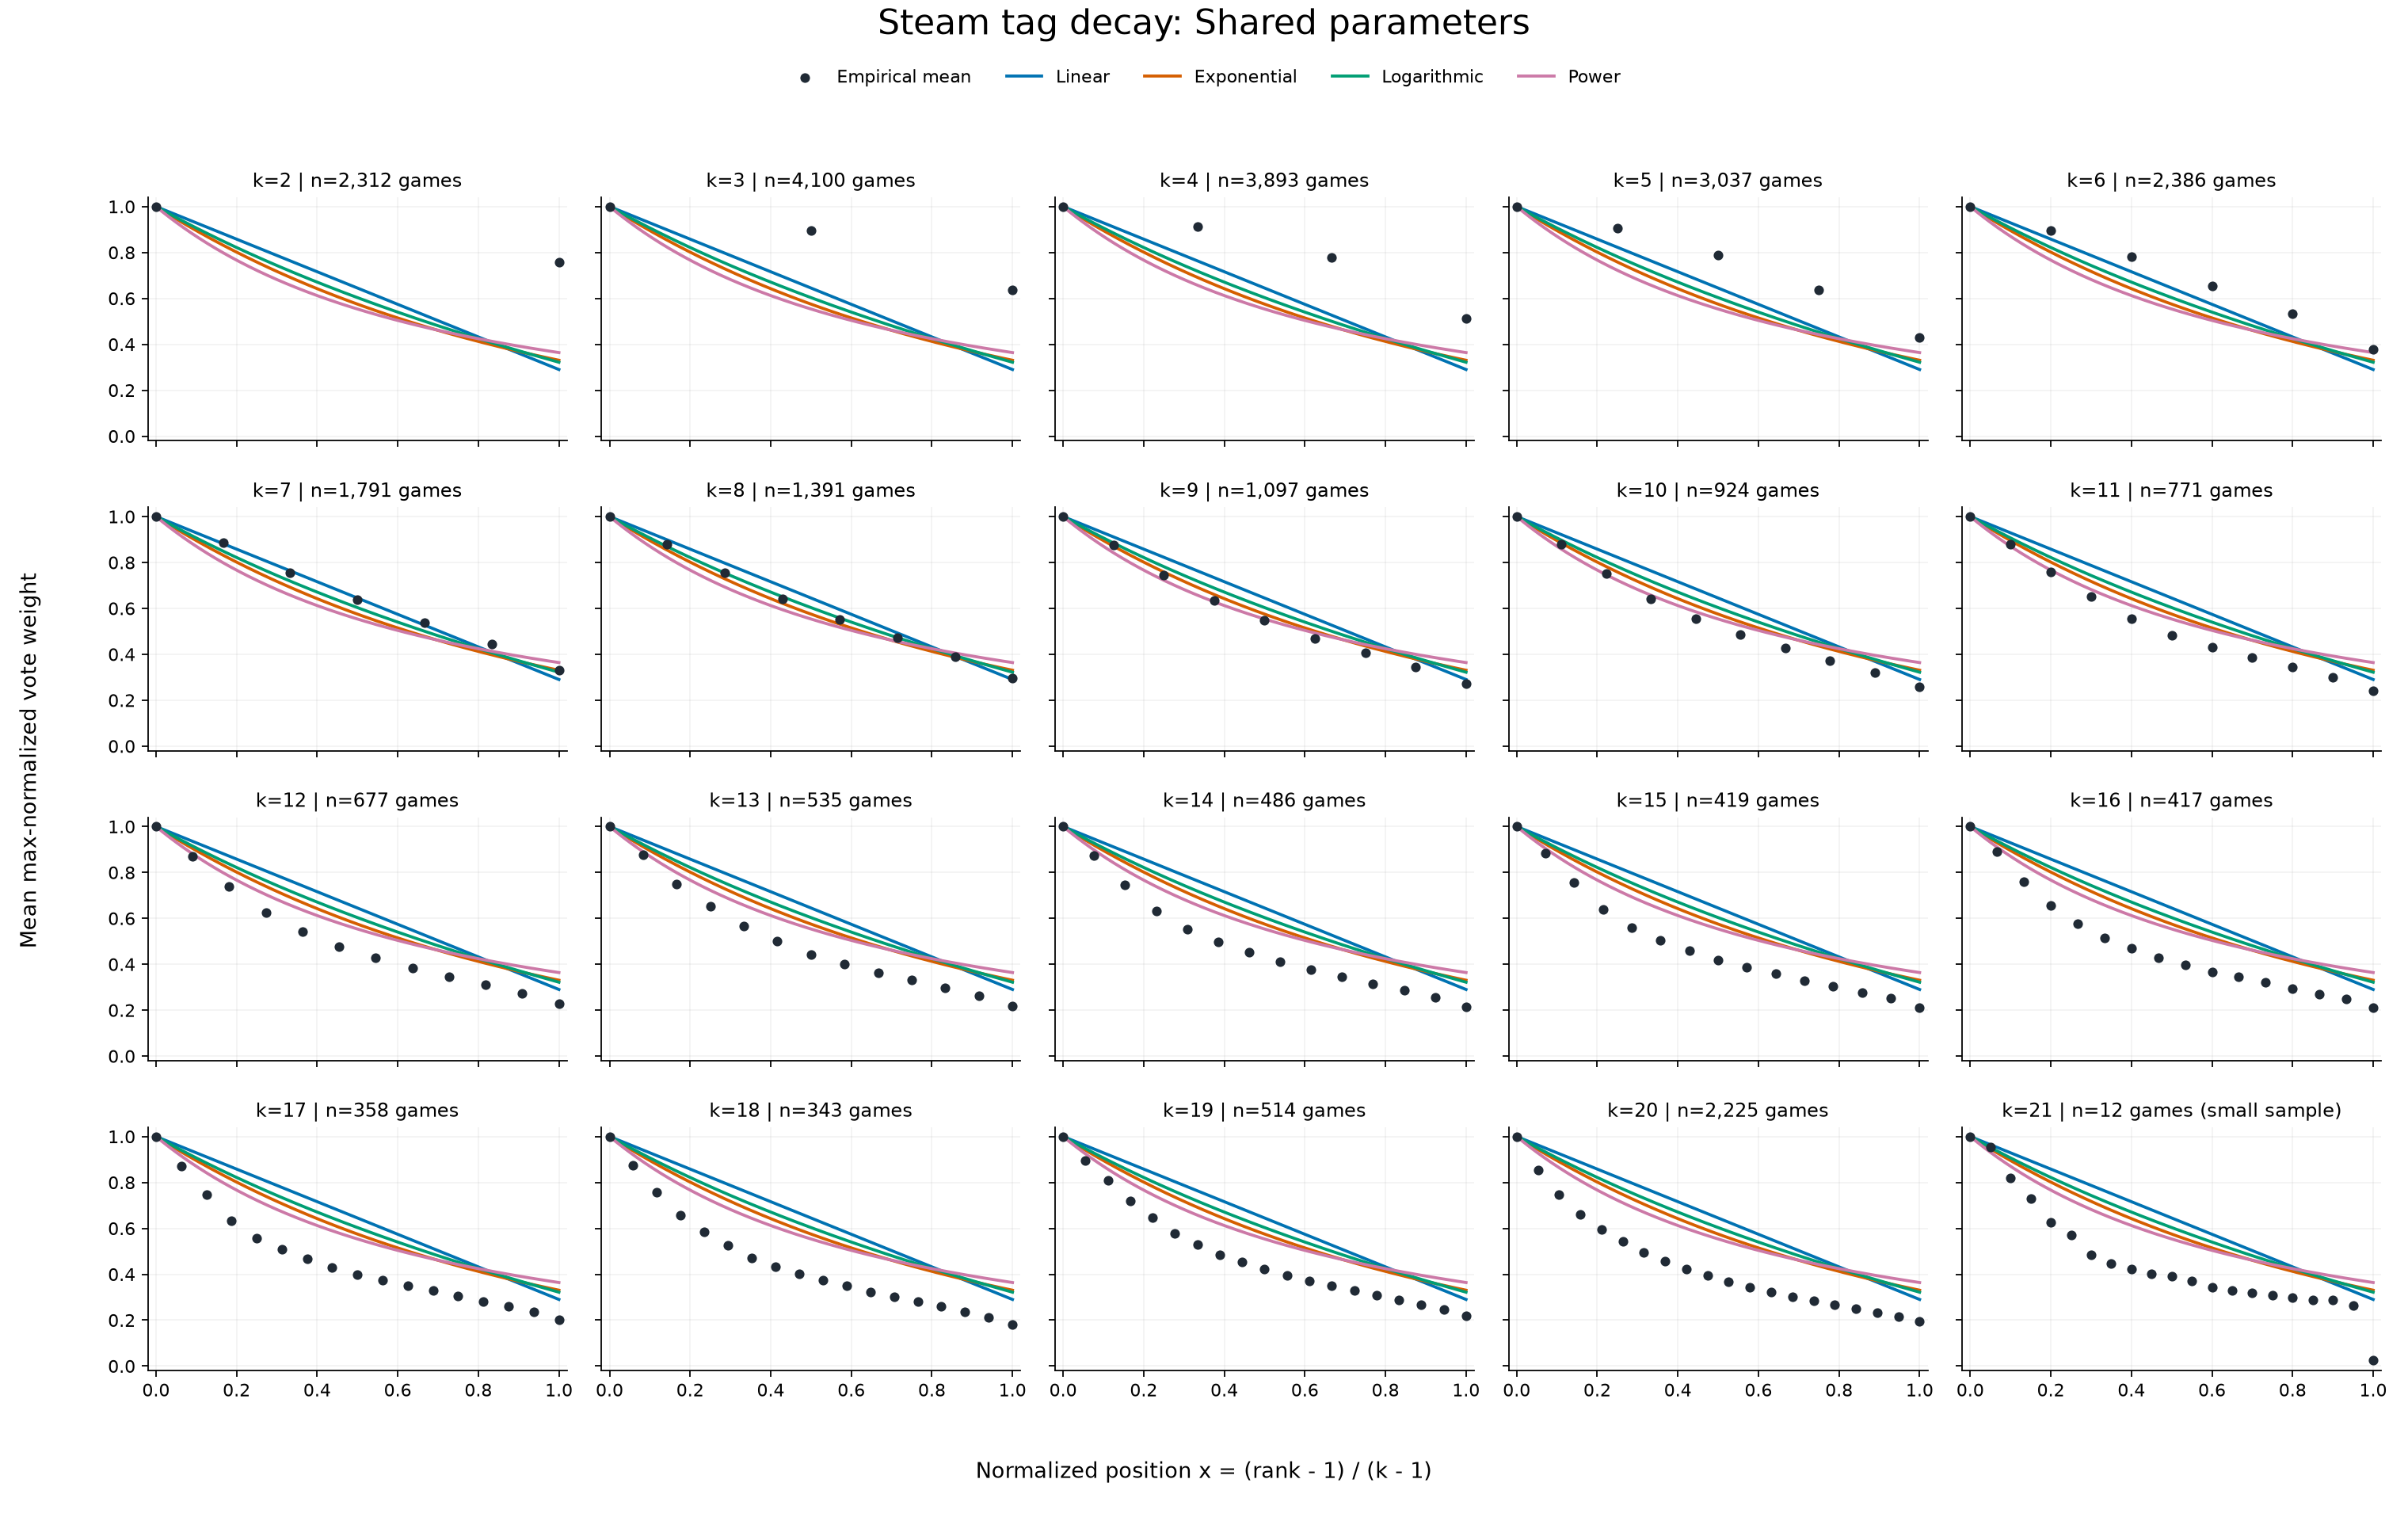

In [12]:
display(Image(filename=str(results_dir / 'shared_fits.png'), width=1500))

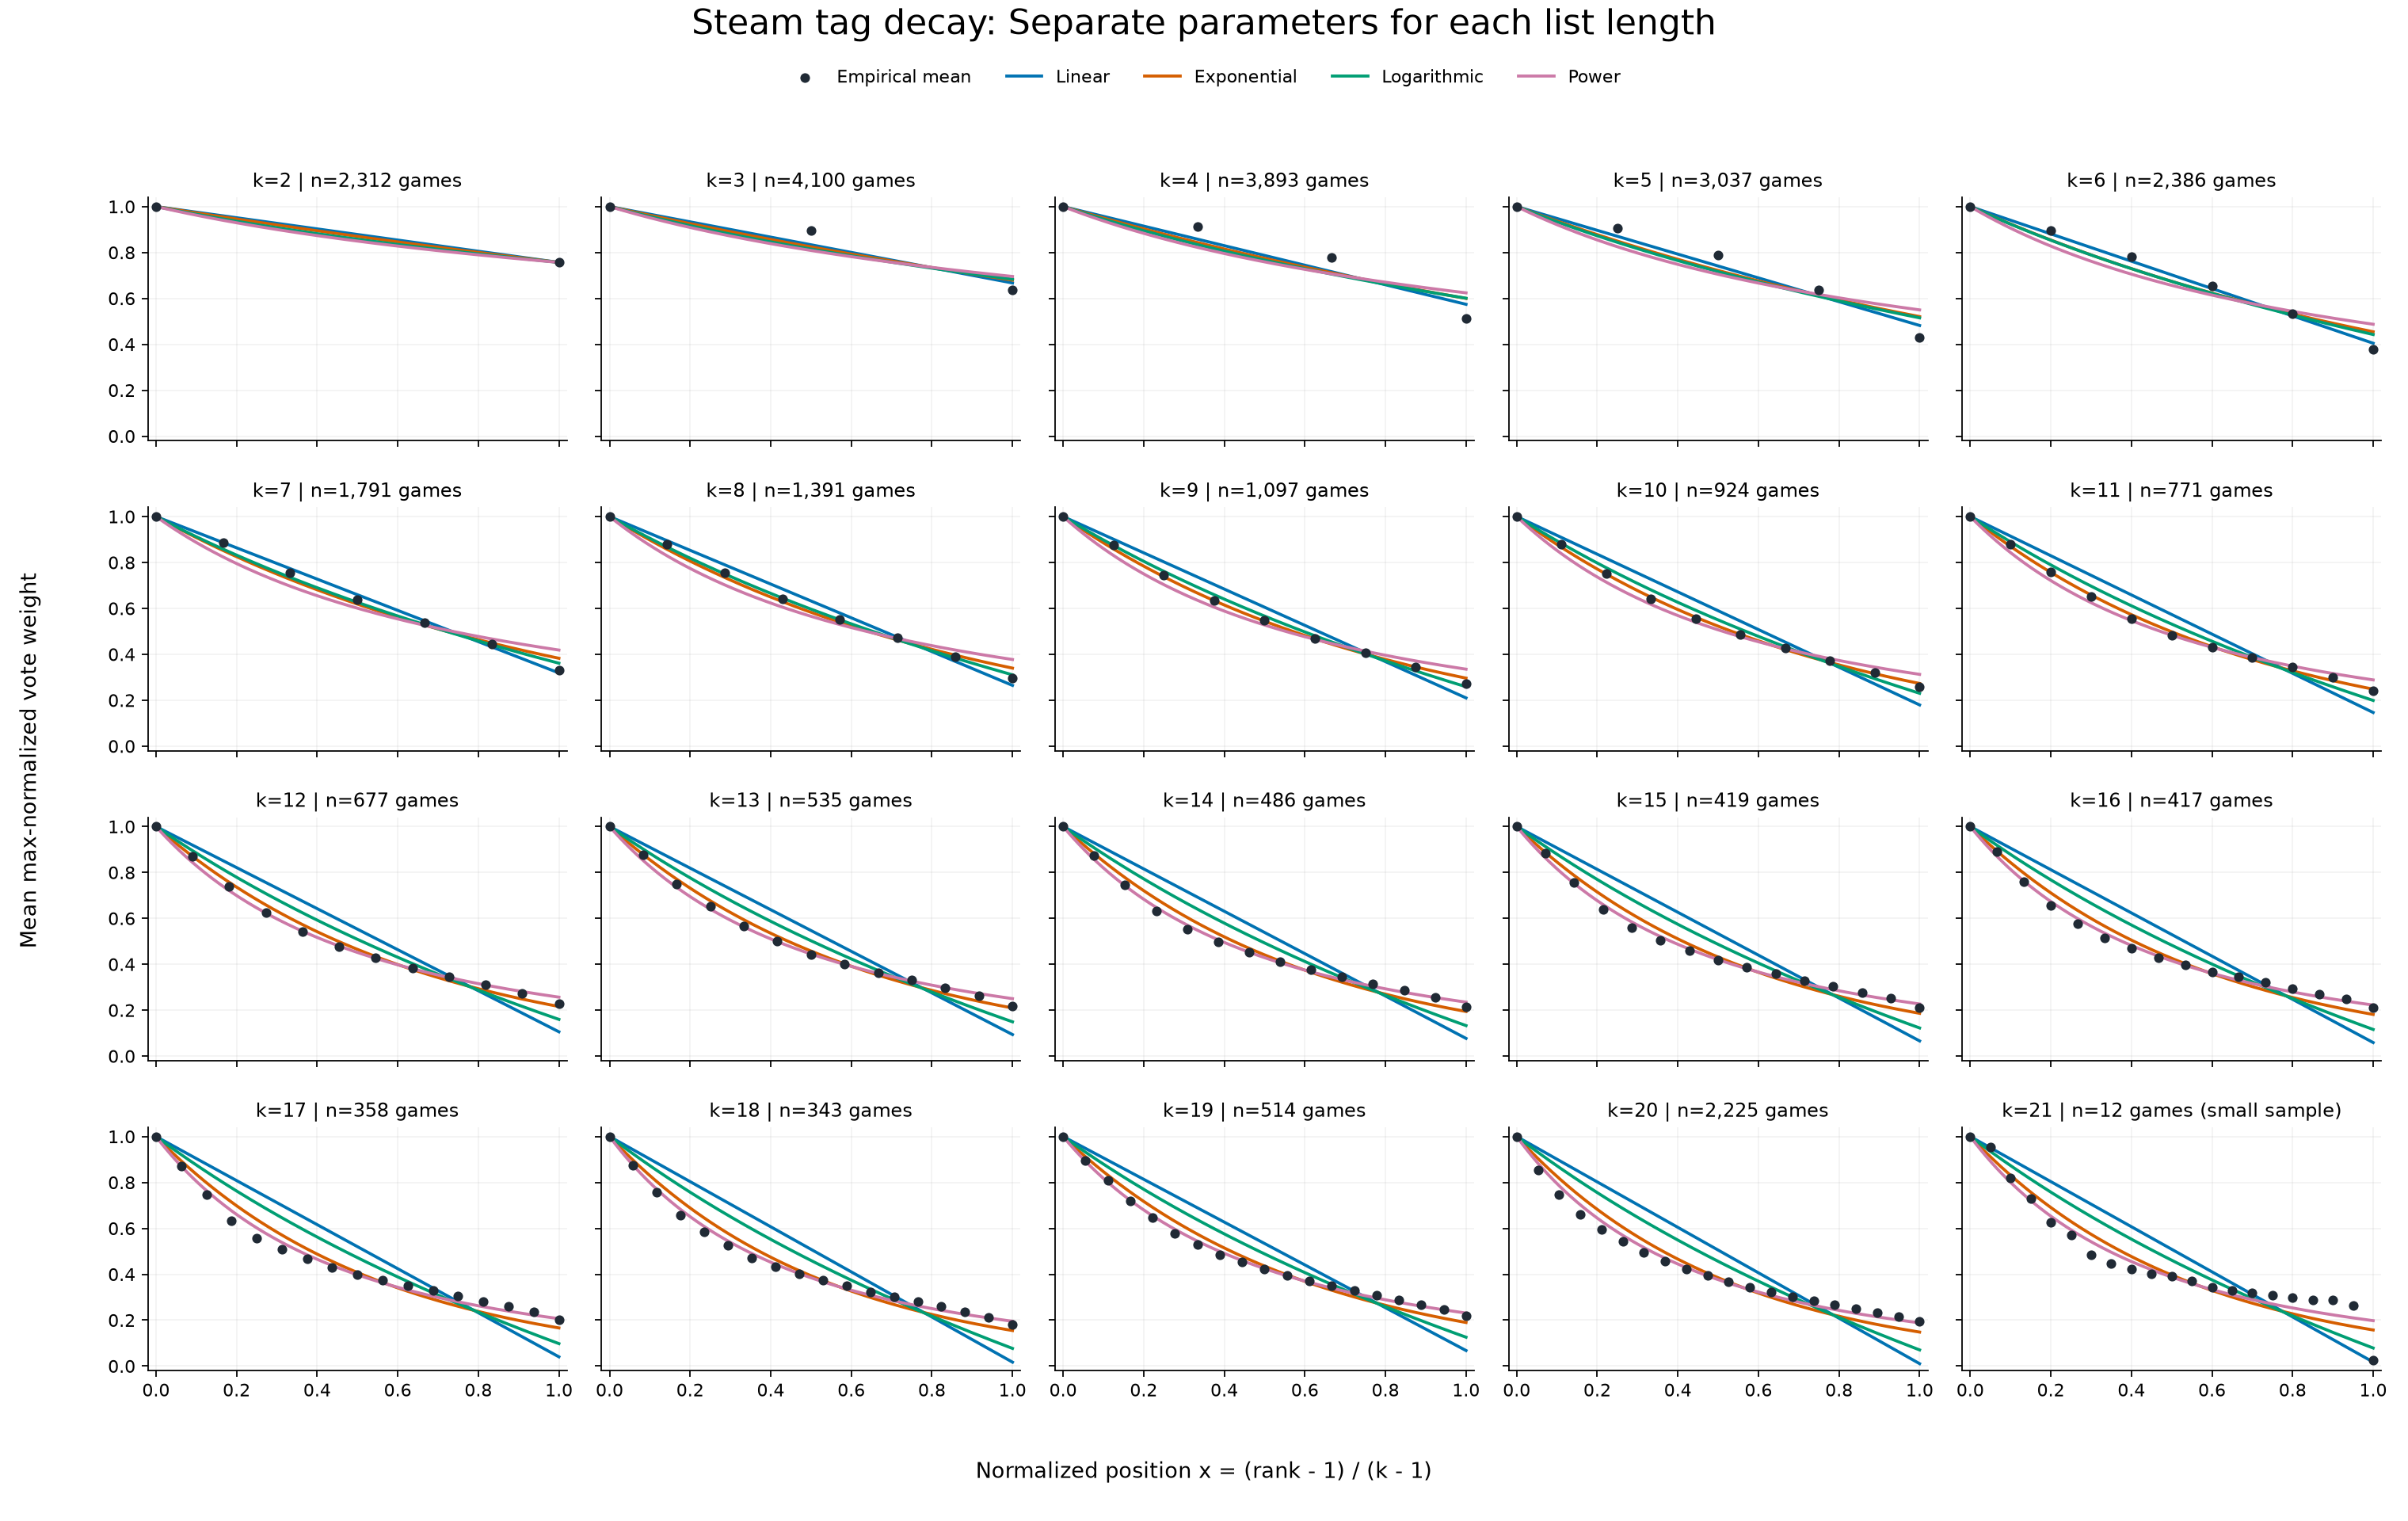

In [13]:
display(Image(filename=str(results_dir / 'per_length_fits.png'), width=1500))

## Per-group errors and fitted parameters

All families and both fitting strategies are exported. The first table compares shared-fit RMSE by list length. The second compares each winning family's shared and per-length errors; the third shows all per-length parameter values.

In [14]:
shared_errors = errors.query("scenario == 'all_groups' and fit_type == 'shared'")
display(shared_errors.pivot(index=['n_tags', 'n_games'], columns='family', values='rmse'))
winners = {selected_model['family'], per_length_winner}
display(errors.loc[errors.scenario.eq('all_groups') & errors.family.isin(winners)]
        .pivot(index=['n_tags', 'n_games'], columns=['family', 'fit_type'], values='rmse'))
display(parameters.query("scenario == 'all_groups' and fit_type == 'per_length'")
        .pivot(index='n_tags', columns='family', values='parameter'))


,family,exponential,linear,logarithmic,power
n_tags,n_games,,,,
2,2312,0.426251,0.466649,0.435008,0.392917
3,4100,0.313629,0.302239,0.303872,0.309626
4,3893,0.240348,0.212977,0.225452,0.245287
5,3037,0.171337,0.137555,0.154339,0.180879
6,2386,0.113668,0.077817,0.095631,0.126383
7,1791,0.052618,0.023152,0.033439,0.070895
8,1391,0.022865,0.032505,0.011407,0.047117
9,1097,0.031330,0.070107,0.045420,0.042739
10,924,0.050402,0.091415,0.066546,0.053417


,family,exponential,power,exponential,power
,fit_type,shared,shared,per_length,per_length
n_tags,n_games,,,,
2,2312,0.426251,0.392917,0.000000,0.000000
3,4100,0.313629,0.309626,0.060238,0.075691
4,3893,0.240348,0.245287,0.074909,0.092459
5,3037,0.171337,0.180879,0.063561,0.083590
6,2386,0.113668,0.126383,0.046876,0.068756
7,1791,0.052618,0.070895,0.029148,0.052975
8,1391,0.022865,0.047117,0.021507,0.045654
9,1097,0.031330,0.042739,0.010422,0.034526


family,exponential,linear,logarithmic,power
n_tags,,,,
2,0.278672,0.243212,0.243212,0.402039
3,0.386398,0.332882,0.316530,0.523841
4,0.510874,0.425859,0.399378,0.680259
5,0.652623,0.518002,0.484786,0.862728
6,0.788321,0.595385,0.557449,1.037088
7,0.960882,0.681292,0.638890,1.257153
8,1.079722,0.735491,0.689580,1.406267
9,1.217163,0.790142,0.741442,1.577417
10,1.298989,0.820674,0.770009,1.677889


## Reuse and interpretation

Load `selected_model.json` and call `weight_vector(n_tags, family, parameter)` during numeric feature construction. Empty lists return an empty array and singleton lists return `[1]`. Longer lists are not truncated; lengths above 21 are extrapolations. These weights retain max normalization and do not apply L2 scaling. Genres and categories are outside this experiment.

In [15]:
model = json.loads((results_dir / 'selected_model.json').read_text())
for k in [0, 1, 5, 21, 40]:
    weights = decay.weight_vector(k, model['family'], model['parameter'])
    print(f'k={k}:', np.round(weights, 4))
    assert len(weights) == k
    assert not k or weights[0] == 1
    assert np.all(np.diff(weights) <= 0)

best_shared_rmse = float(shared_scores.iloc[0]['group_balanced_rmse'])
best_separate_rmse = float(full_scores.query("fit_type == 'per_length'")['group_balanced_rmse'].min())
display(Markdown(
    f"**Finding:** {model['family'].title()} is the closest shared curve among these four families "
    f"(RMSE {best_shared_rmse:.6f}); {per_length_winner} is best with separate parameters "
    f"(RMSE {best_separate_rmse:.6f}). The large error reduction indicates that one normalized-position "
    "curve is a substantial compromise across list lengths. This historical descriptive fit does not "
    "establish recommendation quality. No confidence intervals or held-out recommendation evaluation "
    "were performed. Full equations, scores, limitations, and source hashes are in `results/`."))


k=0: []
k=1: [1.]
k=5: [1.     0.7222 0.5536 0.4421 0.3639]
k=21: [1.     0.9313 0.8702 0.8156 0.7665 0.7222 0.682  0.6455 0.6122 0.5816
 0.5536 0.5277 0.5038 0.4817 0.4612 0.4421 0.4243 0.4077 0.3921 0.3776
 0.3639]
k=40: [1.     0.9637 0.9297 0.8975 0.8673 0.8387 0.8116 0.786  0.7618 0.7387
 0.7168 0.696  0.6762 0.6573 0.6393 0.6221 0.6057 0.59   0.5749 0.5605
 0.5467 0.5335 0.5208 0.5086 0.4969 0.4856 0.4747 0.4643 0.4542 0.4445
 0.4351 0.4261 0.4174 0.4089 0.4008 0.3929 0.3853 0.3779 0.3708 0.3639]


**Finding:** Power is the closest shared curve among these four families (RMSE 0.165817); exponential is best with separate parameters (RMSE 0.040460). The large error reduction indicates that one normalized-position curve is a substantial compromise across list lengths. This historical descriptive fit does not establish recommendation quality. No confidence intervals or held-out recommendation evaluation were performed. Full equations, scores, limitations, and source hashes are in `results/`.

# Length-aware exponential decay: held-out generalization

The earlier section describes full-data curve fits. This section evaluates **new games** under a deterministic within-length split: 60% training, 20% validation, and the remainder test (seed `20261023`). All ranks from a game stay together. Fit parameters from training means only; choose the smooth rate form on validation; freeze candidates before scoring test.

Use $w(r,k)=\exp[-\lambda(k)(r-1)/(k-1)]$. Compare three two-parameter rate functions:

| Rate form | $\lambda(k)$ | Bounds |
|---|---|---|
| Affine | $a+b(k-1)$ | $a,b\ge0$ |
| Power | $a(k-1)^b$ | $a\ge0$, $0\le b\le1$ |
| Saturating | $a[1-\exp(-b(k-1))]$ | $a,b\ge0$ |

Baselines are the four fixed shared families, independently fitted exponential rates for each length, and an absolute-rank exponential $w=\exp[-\beta(r-1)]$. Every baseline is refitted using only training games.

In [16]:
import generalized_decay as generalized

generalization_result = generalized.run_generalization(study_dir)
generalization_dir = generalization_result['output_dir']
generalization_scores = pd.DataFrame(generalization_result['scores'])
generalization_errors = pd.DataFrame(generalization_result['errors'])
smooth_name = generalization_result['selected_smooth']
print('Validation-selected smooth model:', smooth_name)
print('Validation-selected best candidate overall:', generalization_result['selected_overall'])
print('Game counts:', {split: sum(len(block.appids) for block in blocks.values())
                       for split, blocks in generalization_result['splits'].items()})
for split in ('train', 'validation', 'test'):
    appids = {int(appid) for block in generalization_result['splits'][split].values() for appid in block.appids}
    for other in ('train', 'validation', 'test'):
        if other != split:
            other_appids = {int(appid) for block in generalization_result['splits'][other].values() for appid in block.appids}
            assert not appids.intersection(other_appids)
print('All three game sets are disjoint.')


Validation-selected smooth model: length_saturating_exponential
Validation-selected best candidate overall: per_length_exponential
Game counts: {'train': 16605, 'validation': 5530, 'test': 5553}
All three game sets are disjoint.


## Validation and test errors

**Mean-curve error** compares predictions with held-out empirical group means. **Individual-game error** compares predictions with each held-out game's max-normalized vote vector. Each overall MSE is an equal-weight average across lengths; RMSE is its square root. Rank 1 is excluded. Sample-weighted metrics are also exported.

Within each length, individual-game MSE equals mean-curve MSE plus within-group variance. For fixed splits this variance is common to all models; the two macro MSE rankings therefore agree. Validation selects the smooth form using mean-curve macro MSE. Test scores do not change model selection.

In [17]:
columns = ['model', 'n_parameters', 'mean_curve_group_balanced_rmse',
           'game_group_balanced_rmse', 'mean_curve_sample_weighted_rmse',
           'game_sample_weighted_rmse']
for split in ['validation', 'test']:
    print(split.upper())
    rows = generalization_scores.query("split == @split and scenario == 'all_lengths'")
    display(rows.sort_values('mean_curve_group_balanced_mse')[columns])
pd.testing.assert_frame_equal(generalization_scores, pd.read_csv(generalization_dir / 'model_scores.csv'),
                              check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
assert np.allclose(generalization_errors.game_mse,
                   generalization_errors.mean_curve_mse + generalization_errors.within_group_variance)
print('Exported scores match notebook objects; individual-game error decomposition holds.')


VALIDATION


,model,n_parameters,mean_curve_group_balanced_rmse,game_group_balanced_rmse,mean_curve_sample_weighted_rmse,game_sample_weighted_rmse
26,per_length_exponential,20,0.045477,0.188561,0.050619,0.225472
34,length_saturating_exponential,2,0.047297,0.189008,0.054781,0.226442
32,length_power_exponential,2,0.047512,0.189062,0.055053,0.226508
30,length_affine_exponential,2,0.052784,0.190456,0.059075,0.227519
28,raw_rank_exponential,1,0.069956,0.195911,0.082446,0.234676
24,shared_power,1,0.172858,0.251728,0.214914,0.307348
20,shared_exponential,1,0.178811,0.255853,0.219583,0.310631
22,shared_logarithmic,1,0.185258,0.260399,0.217693,0.309298
18,shared_linear,1,0.200769,0.271653,0.224829,0.314361


TEST


,model,n_parameters,mean_curve_group_balanced_rmse,game_group_balanced_rmse,mean_curve_sample_weighted_rmse,game_sample_weighted_rmse
44,per_length_exponential,20,0.042258,0.187755,0.050144,0.225384
52,length_saturating_exponential,2,0.045610,0.188538,0.053846,0.226236
50,length_power_exponential,2,0.047241,0.188938,0.052981,0.226032
48,length_affine_exponential,2,0.054143,0.190781,0.056821,0.226963
46,raw_rank_exponential,1,0.075244,0.197807,0.084077,0.235271
42,shared_power,1,0.165070,0.246402,0.210347,0.304186
38,shared_exponential,1,0.170874,0.250328,0.214925,0.307370
40,shared_logarithmic,1,0.176841,0.254438,0.212832,0.305910
36,shared_linear,1,0.192087,0.265261,0.219829,0.310819


Exported scores match notebook objects; individual-game error decomposition holds.


**Selected rate equation:** `lambda(k) = a*(1-exp(-b*(k-1)))`. **Training-only parameters used for evaluation:** `{'a': 2.2072768579717916, 'b': 0.0969780937258659}`. **All-data refit for reuse:** `{'a': 2.249150856857026, 'b': 0.0946333263878718}`. The all-data refit has no independent test score in this experiment.

,n_tags,train_games,validation_games,test_games,separate_training_lambda,smooth_training_lambda,smooth_all_data_lambda
0,2,1387,462,463,0.281993,0.204006,0.203084
1,3,2460,820,820,0.382465,0.389156,0.387831
2,4,2335,778,780,0.512891,0.557194,0.555896
3,5,1822,607,608,0.653657,0.709702,0.708786
4,6,1431,477,478,0.771826,0.848114,0.847871
5,7,1074,358,359,0.966517,0.973733,0.974397
6,8,834,278,279,1.086866,1.087742,1.089499
7,9,658,219,220,1.233769,1.191214,1.194208
8,10,554,184,186,1.291793,1.285123,1.289463
9,11,462,154,155,1.381575,1.370352,1.376117


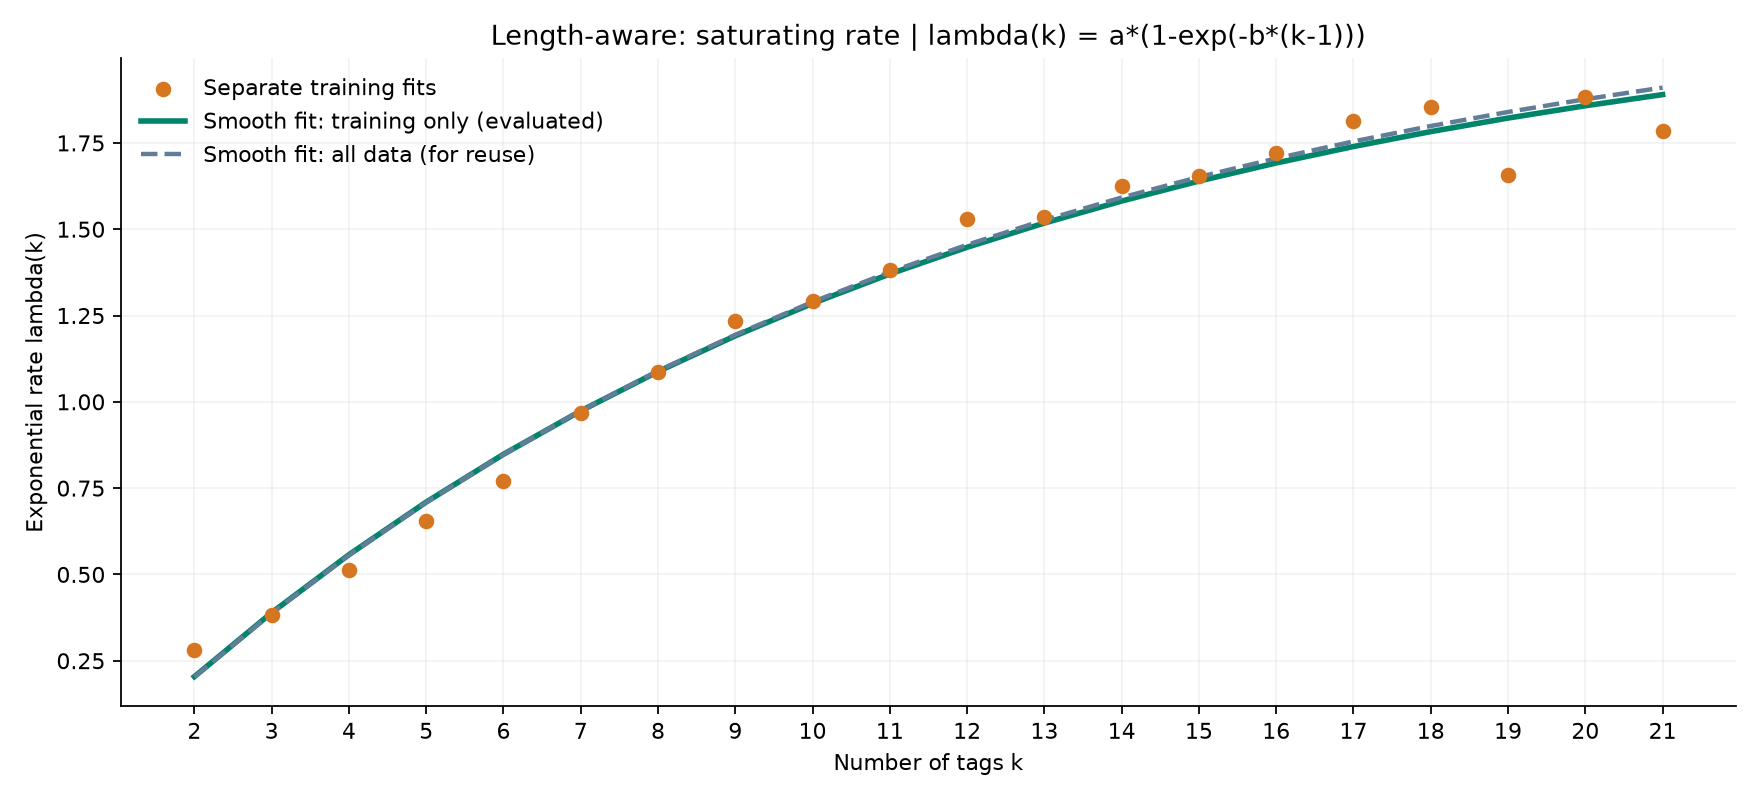

In [18]:
evaluation_model = next(m for m in generalization_result['models'] if m['name'] == smooth_name)
final_length_model = generalization_result['final_model']
display(Markdown(f"**Selected rate equation:** `{evaluation_model['rate_equation']}`. "
                 f"**Training-only parameters used for evaluation:** `{evaluation_model['parameters']}`. "
                 f"**All-data refit for reuse:** `{final_length_model['parameters']}`. "
                 "The all-data refit has no independent test score in this experiment."))
display(pd.read_csv(generalization_dir / 'length_rates.csv'))
display(Image(filename=str(generalization_dir / 'length_rates.png'), width=1100))


## Uncertainty and sparse-length sensitivity

Use 2,000 paired bootstrap resamples of test games within each length, holding the fitted models fixed. Report **smooth-minus-per-length MSE**: positive favors the separate rates. Within-length variance cancels, so this difference is identical for mean-curve and individual-game macro MSE.

These intervals cover test-sampling uncertainty conditional on the fitted models; they do not include training or model-selection uncertainty. Scoring without `k=21` uses the same fitted models. The 21-tag group contributes only three test games, which limits its uncertainty estimate.

In [19]:
bootstrap_summary = pd.DataFrame(generalization_result['bootstrap']['results']).T
display(bootstrap_summary)
sensitivity = generalization_scores.loc[generalization_scores.split.eq('test') &
    generalization_scores.model.isin([smooth_name, 'per_length_exponential'])]
display(sensitivity[['model', 'scenario', 'mean_curve_group_balanced_rmse',
                     'game_group_balanced_rmse', 'mean_curve_sample_weighted_rmse']])
print('Mean-curve MSE difference interval includes zero:',
      generalization_result['bootstrap']['results']['all_lengths']['interval_includes_zero'])


,mse_difference,ci95_lower,ci95_upper,interval_includes_zero
all_lengths,0.000295,0.000057,0.000546,False
without_k21,0.000261,0.000056,0.000483,False


,model,scenario,mean_curve_group_balanced_rmse,game_group_balanced_rmse,mean_curve_sample_weighted_rmse
44,per_length_exponential,all_lengths,0.042258,0.187755,0.050144
45,per_length_exponential,without_k21,0.041151,0.191112,0.050139
52,length_saturating_exponential,all_lengths,0.045610,0.188538,0.053846
53,length_saturating_exponential,without_k21,0.044208,0.191794,0.053838


Mean-curve MSE difference interval includes zero: False


## Stress test: omit each length from training

Keep the validation-selected functional form fixed, omit one length's training games, refit on the other lengths, and predict the omitted length's test games. Interior lengths test interpolation; the two edge lengths test extrapolation. The form itself was selected with validation games at all lengths, so this is a stress test rather than nested model selection for wholly unseen lengths.

In [20]:
omitted = pd.DataFrame(generalization_result['leave_length_out'])
display(omitted[['held_out_length', 'n_games', 'mean_curve_rmse', 'game_rmse', 'length_extrapolation']])
print('Leave-length-out macro RMSE:', np.sqrt(omitted.mean_curve_mse.mean()))
selected_test_errors = generalization_errors.loc[generalization_errors.split.eq('test') &
    generalization_errors.model.isin([smooth_name, 'per_length_exponential'])]
display(selected_test_errors.pivot(index=['n_tags', 'n_games'], columns='model', values='mean_curve_rmse'))


,held_out_length,n_games,mean_curve_rmse,game_rmse,length_extrapolation
0,2,463,0.066050,0.318517,True
1,3,820,0.056794,0.276852,False
2,4,780,0.080731,0.254615,False
3,5,608,0.072428,0.235947,False
4,6,478,0.046030,0.223261,False
5,7,359,0.030666,0.196070,False
6,8,279,0.021553,0.188818,False
7,9,220,0.025013,0.179551,False
8,10,186,0.008709,0.169873,False
9,11,155,0.019107,0.149789,False


Leave-length-out macro RMSE: 0.04656750217023472


,model,length_saturating_exponential,per_length_exponential
n_tags,n_games,,
2,463,0.059941,0.001238
3,820,0.056830,0.057205
4,780,0.079538,0.075757
5,608,0.071140,0.067235
6,478,0.045800,0.052877
7,359,0.030566,0.029776
8,279,0.021542,0.021418
9,220,0.025542,0.033614
10,186,0.008708,0.008853


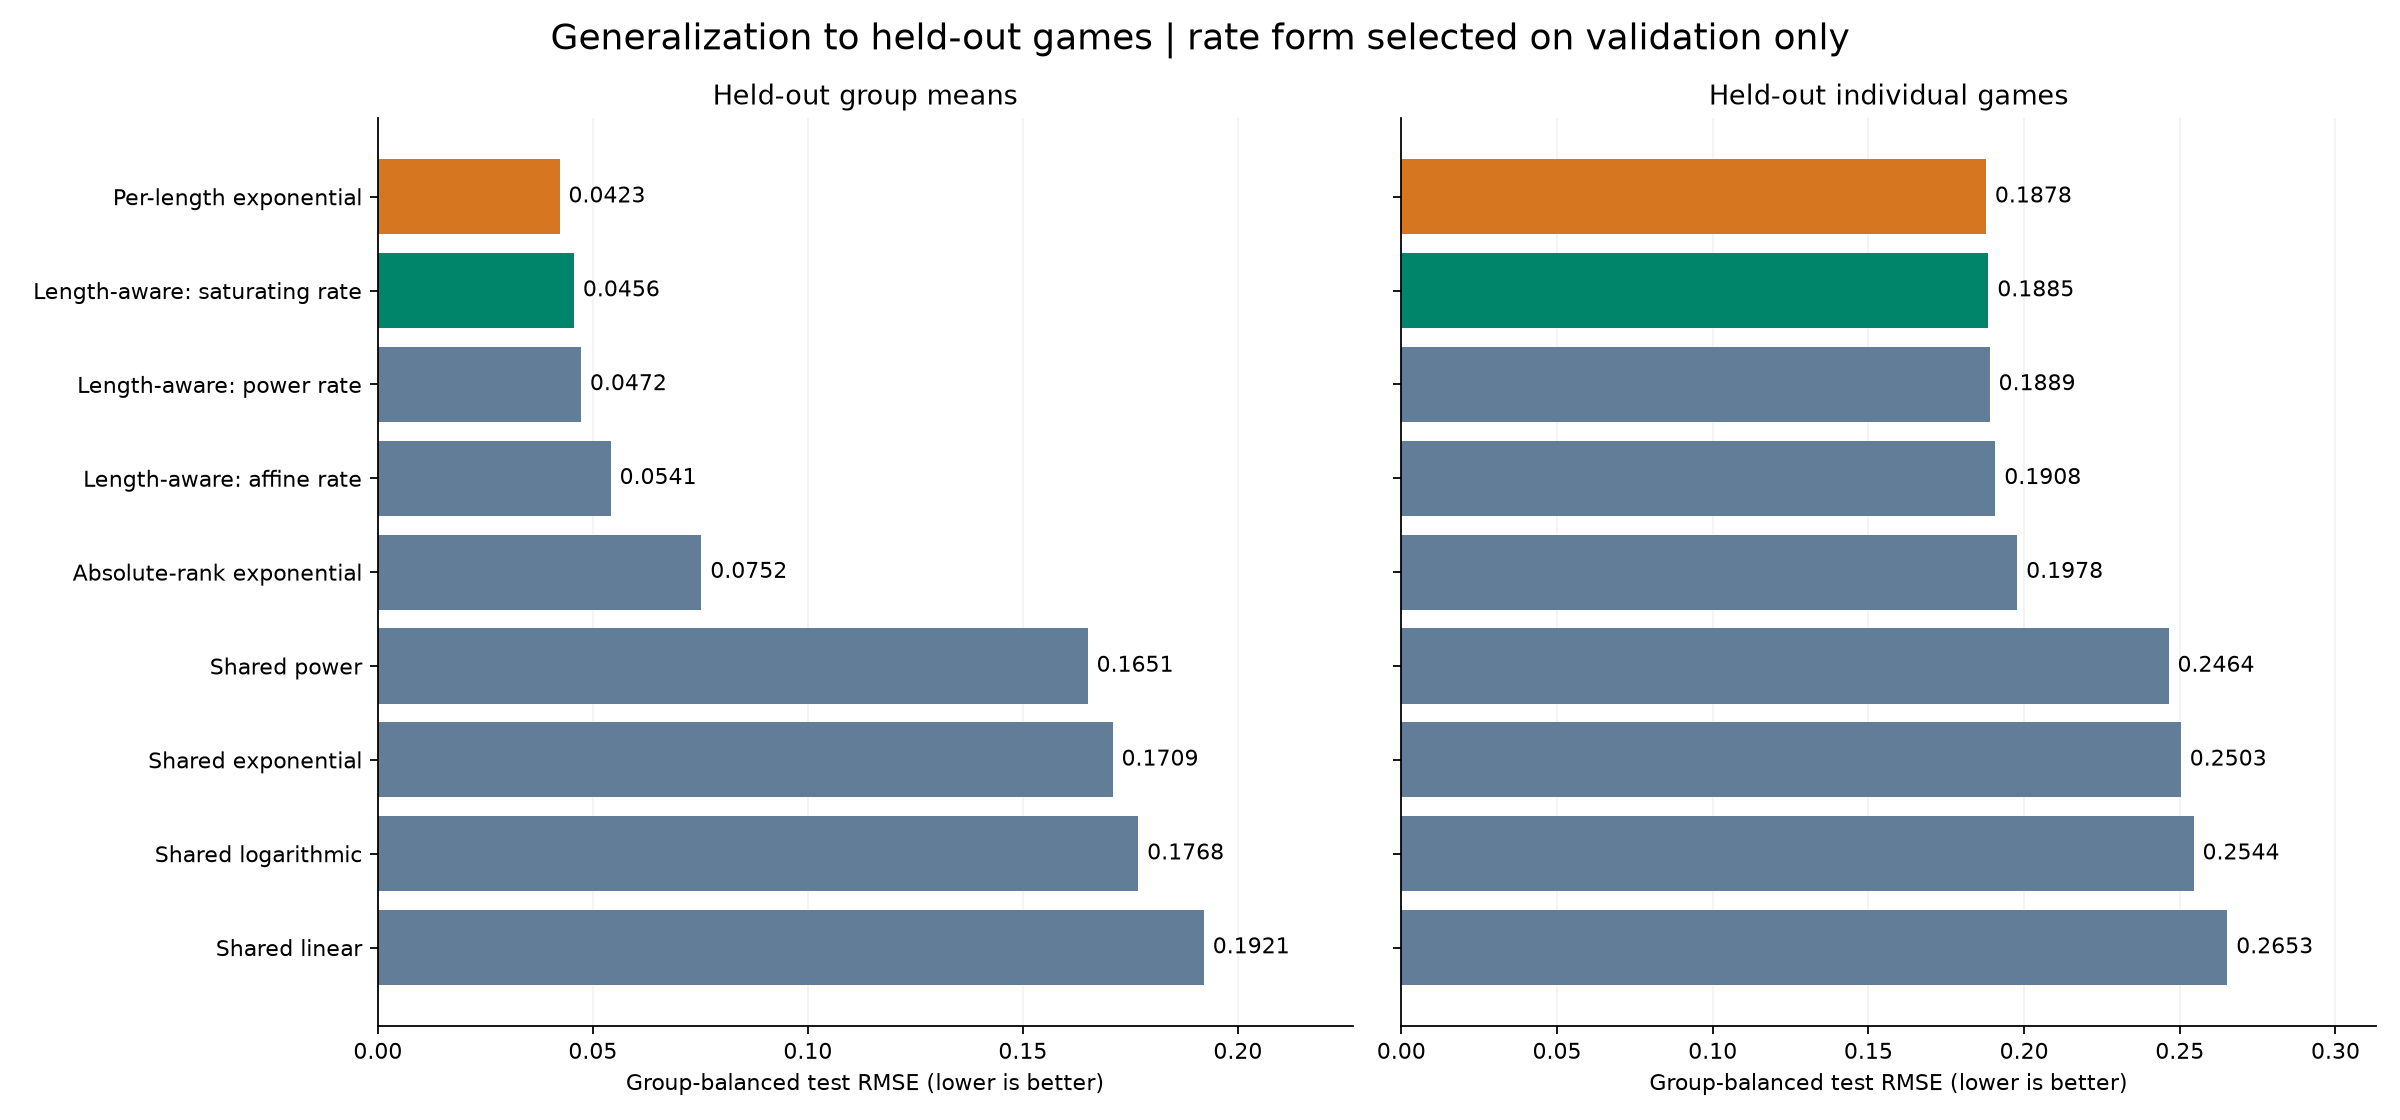

In [21]:
display(Image(filename=str(generalization_dir / 'test_comparison.png'), width=1300))

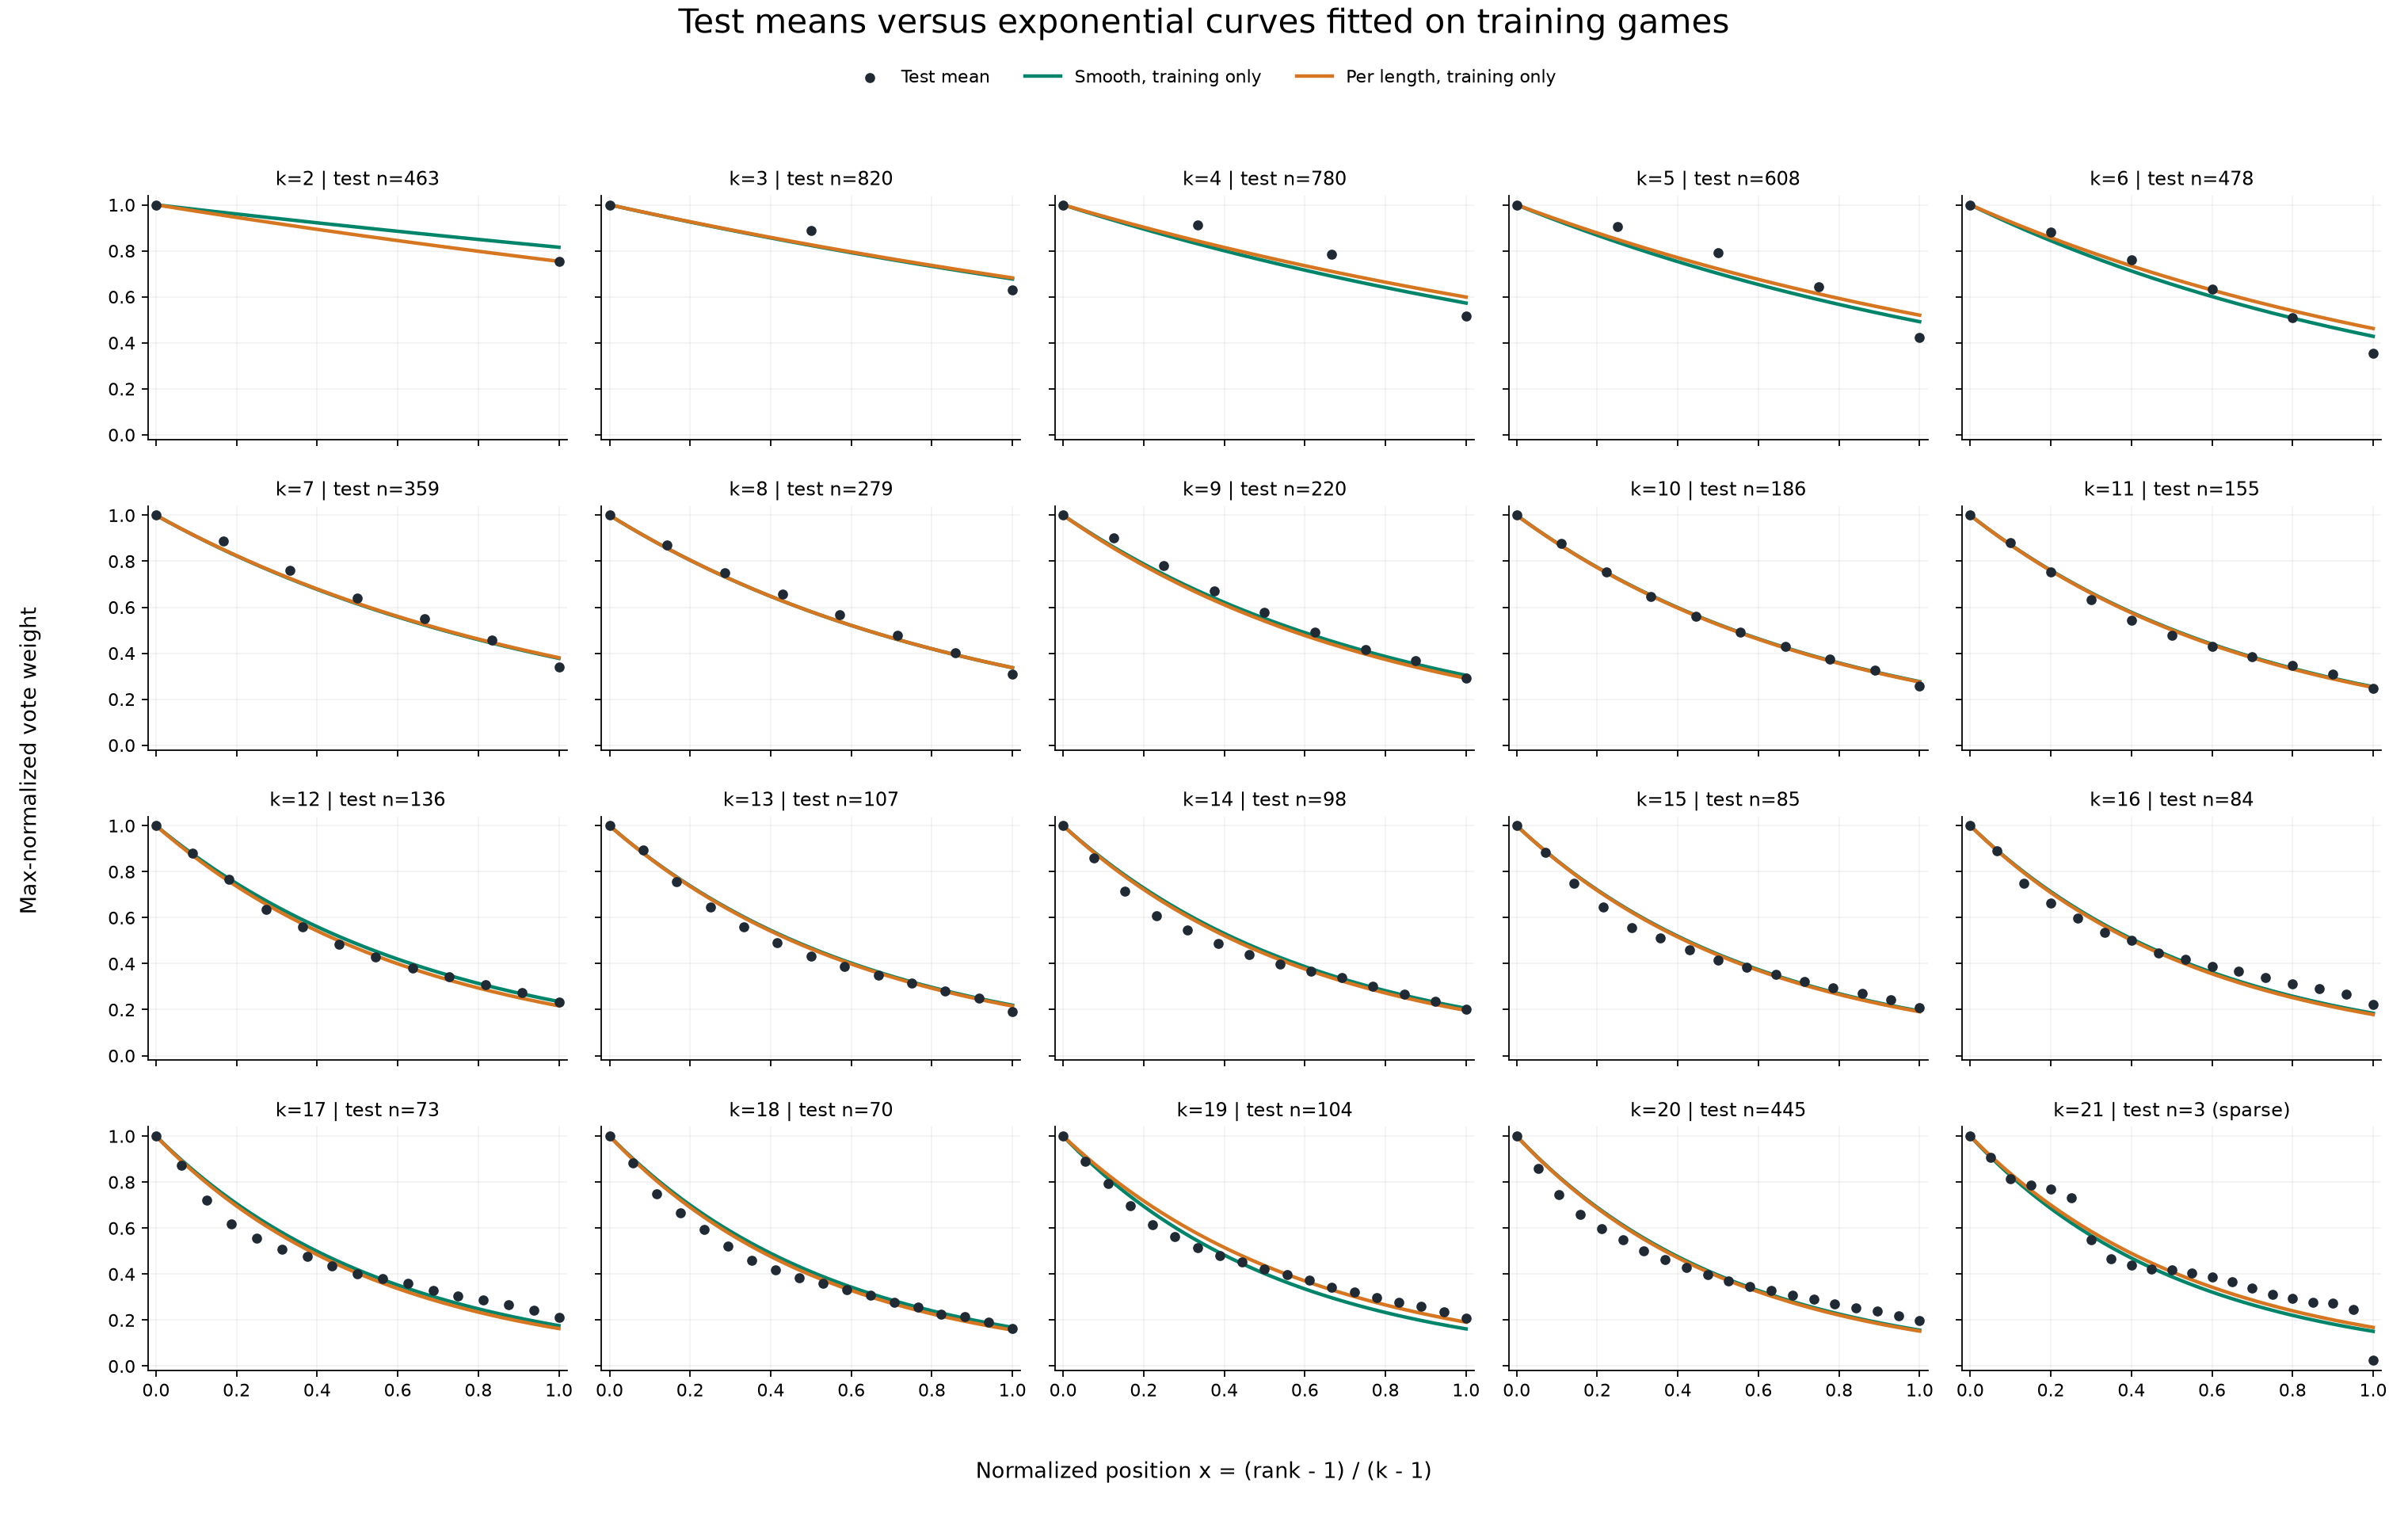

In [22]:
display(Image(filename=str(generalization_dir / 'test_curves.png'), width=1500))

## Practical result and reuse

The smooth model is a two-parameter compromise. The independently fitted exponential baseline retains the best measured validation/test accuracy. Both should remain visible in the comparison.

The holdout is retrospective within the historical dataset already explored above; it does not establish recommendation quality or generalization to new datasets/time periods. Lengths above 21 are extrapolations. The saved all-data refit is intended for numeric feature construction, and preserves rank-1 normalization.

In [23]:
test_table = generalization_scores.query("split == 'test' and scenario == 'all_lengths'").set_index('model')
smooth_rmse = float(test_table.loc[smooth_name, 'mean_curve_group_balanced_rmse'])
separate_rmse = float(test_table.loc['per_length_exponential', 'mean_curve_group_balanced_rmse'])
shared_rmse = float(test_table.loc['shared_power', 'mean_curve_group_balanced_rmse'])
display(Markdown(f"**Test result:** the selected smooth function has mean-curve RMSE "
                 f"**{smooth_rmse:.6f}**, versus **{separate_rmse:.6f}** for separate exponential rates "
                 f"and **{shared_rmse:.6f}** for the fixed shared power rule. "
                 "Use the smooth equation when compactness and support for new lengths matter; "
                 "use the separate-rate benchmark when accuracy at observed lengths is the priority."))

reuse_model = json.loads((generalization_dir / 'selected_length_aware_model.json').read_text())
for k in [0, 1, 5, 21, 40]:
    weights = generalized.predict_weights(k, reuse_model)
    print(f'k={k}:', np.round(weights, 4))
    assert len(weights) == k and np.all(np.diff(weights) <= 0)


**Test result:** the selected smooth function has mean-curve RMSE **0.045610**, versus **0.042258** for separate exponential rates and **0.165070** for the fixed shared power rule. Use the smooth equation when compactness and support for new lengths matter; use the separate-rate benchmark when accuracy at observed lengths is the priority.

k=0: []
k=1: [1.]
k=5: [1.     0.8376 0.7016 0.5877 0.4922]
k=21: [1.     0.9089 0.8261 0.7509 0.6825 0.6203 0.5638 0.5124 0.4657 0.4233
 0.3848 0.3497 0.3179 0.2889 0.2626 0.2387 0.2169 0.1972 0.1792 0.1629
 0.148 ]
k=40: [1.     0.9453 0.8936 0.8448 0.7986 0.7549 0.7136 0.6746 0.6377 0.6029
 0.5699 0.5387 0.5093 0.4814 0.4551 0.4302 0.4067 0.3845 0.3634 0.3436
 0.3248 0.307  0.2902 0.2744 0.2594 0.2452 0.2318 0.2191 0.2071 0.1958
 0.1851 0.175  0.1654 0.1564 0.1478 0.1397 0.1321 0.1249 0.118  0.1116]
